In [28]:
#!pip install pillow numpy matplotlib

In [29]:
## 0. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

In [30]:

def load_hand_images(root_directory, image_size=28):
    root = Path(root_directory)

    if not root.is_dir():
        raise FileNotFoundError(f"Directory not found: {root}")

    # Original Sign MNIST label convention:
    # A=0, B=1, ..., I=8, K=10, ..., Y=24
    # J=9 and Z=25 are excluded.
    label_map = {
        letter: index
        for index, letter in enumerate("ABCDEFGHIKLMNOPQRSTUVWXY")
    }

    supported_extensions = {".jpg", ".jpeg", ".png"}

    images = []
    labels = []
    file_paths = []

    for folder in sorted(root.iterdir()):
        if not folder.is_dir():
            continue

        letter = folder.name.upper()

        if letter not in label_map:
            print(f"Skipping unsupported folder: {folder.name}")
            continue

        # Recursively includes images in any nested subfolders.
        for path in sorted(folder.rglob("*")):
            if path.suffix.lower() not in supported_extensions:
                continue

            try:
                with Image.open(path) as original:
                    # Apply camera orientation before processing.
                    oriented = ImageOps.exif_transpose(original)

                    # Composite transparent PNGs onto white.
                    rgba = oriented.convert("RGBA")
                    background = Image.new(
                        "RGBA", rgba.size, (255, 255, 255, 255)
                    )
                    rgb = Image.alpha_composite(
                        background, rgba
                    ).convert("RGB")

                    grayscale = ImageOps.grayscale(rgb)

                    # Preserve proportions and pad the shorter side.
                    prepared = ImageOps.pad(
                        grayscale,
                        (image_size, image_size),
                        method=Image.Resampling.LANCZOS,
                        color=255,
                    )

                    pixels = np.array(prepared, dtype=np.uint8)

                images.append(pixels)
                labels.append(label_map[letter])
                file_paths.append(str(path))

            except (OSError, ValueError) as error:
                print(f"Cannot read {path}: {error}")

    if not images:
        raise ValueError("No readable images found in supported letter folders.")

    # CNN shape: (number_of_images, height, width, channels)
    X = np.stack(images)[..., np.newaxis]
    y = np.array(labels, dtype=np.int64)

    return X, y, file_paths

In [31]:
X_images, y_images, image_paths = load_hand_images(
    "../data/asl_dataset"
)
# Normalize the image pixel values to the range [0, 1].
X_images = X_images.astype('float32') / 255.0


print(X_images.min(), X_images.max())

print("Images:", X_images.shape)
print("Labels:", y_images.shape)
print("Pixel range:", X_images.min(), X_images.max())

Skipping unsupported folder: 0
Skipping unsupported folder: 1
Skipping unsupported folder: 2
Skipping unsupported folder: 3
Skipping unsupported folder: 4
Skipping unsupported folder: 5
Skipping unsupported folder: 6
Skipping unsupported folder: 7
Skipping unsupported folder: 8
Skipping unsupported folder: 9
Skipping unsupported folder: J
Skipping unsupported folder: Z
0.0 1.0
Images: (24000, 28, 28, 1)
Labels: (24000,)
Pixel range: 0.0 1.0


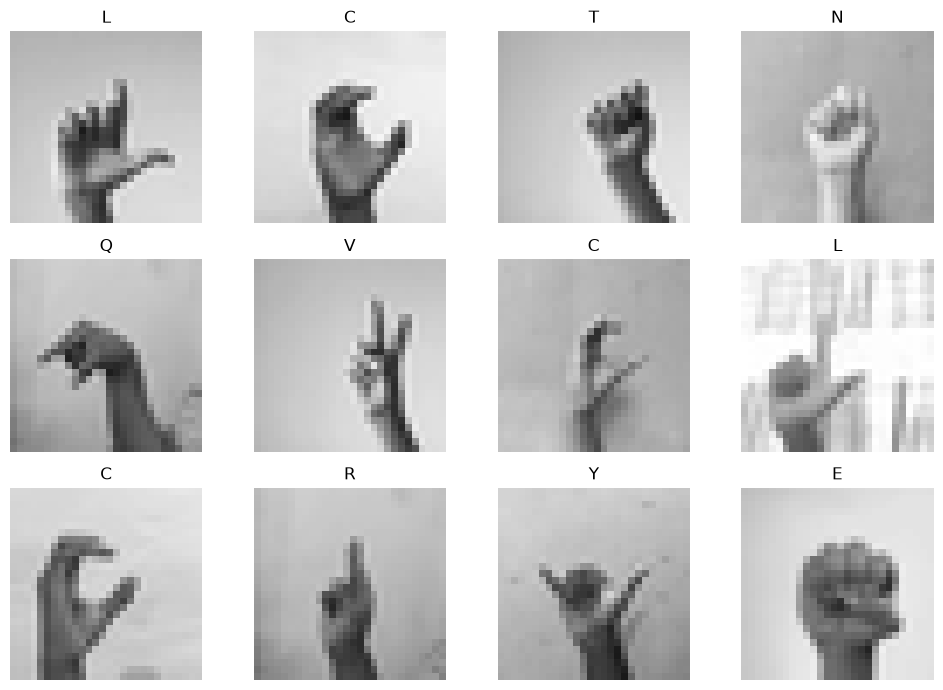

In [32]:
import matplotlib.pyplot as plt

# Display a random selection of hand gesture images with their corresponding labels.
count = min(12, len(X_images))
# Select random indices for displaying images.
indices = np.random.default_rng(42).choice(
    len(X_images), size=count, replace=False
)

# Create a 3x4 grid for displaying the images.
fig, axes = plt.subplots(3, 4, figsize=(10, 7))

# Turn off axes for all subplots initially.
for ax in axes.flat:
    ax.axis("off")

# Display the selected images with their corresponding labels.
letters = "ABCDEFGHIKLMNOPQRSTUVWXY"
for ax, index in zip(axes.flat, indices):
    ax.imshow(X_images[index, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(letters[int(y_images[index])])
# Adjust layout and display the figure.
plt.tight_layout()
plt.show()

In [33]:
X_train, X_val, y_train, y_val = train_test_split(X_images, y_images, test_size=0.2, random_state=42, stratify=y_images)

In [34]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

mnist_df = pd.read_csv("../data/sign_mnist_train.csv")

# Prepare MNIST pixels directly from the CSV.
X_mnist = (
    mnist_df.drop(columns="label")
    .to_numpy(dtype=np.float32)
    .reshape(-1, 28, 28, 1)
    / 255.0
)

# Match the mapping used by your image-folder loader.
letters = "ABCDEFGHIKLMNOPQRSTUVWXY"

original_to_new = {
    ord(letter) - ord("A"): index
    for index, letter in enumerate(letters)
}

mapped_labels = mnist_df["label"].map(original_to_new)

if mapped_labels.isna().any():
    raise ValueError("Unexpected MNIST labels found.")

y_mnist = mapped_labels.to_numpy(dtype=np.int64)

In [35]:
X_mnist_train, X_mnist_val, y_mnist_train, y_mnist_val = (
    train_test_split(
        X_mnist,
        y_mnist,
        test_size=0.2,
        random_state=42,
        stratify=y_mnist,
    )
)

# X_train and y_train are your existing downloaded-image training split.
X_train_combined = np.concatenate(
    [X_train, X_mnist_train], axis=0
)

y_train_combined = np.concatenate(
    [y_train, y_mnist_train], axis=0
)

In [36]:
model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.4),

        layers.Dense(24, activation='softmax')
    ])

In [37]:
model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,344 (1.62 MB)

 Trainable params: 423,896 (1.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [38]:
early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

history = model.fit(
        X_train_combined, y_train_combined,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=64,
        callbacks=[early_stop],
        shuffle=True,
        verbose=1
    )

Epoch 1/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 78s 102ms/step - accuracy: 0.8798 - loss: 0.5202 - val_accuracy: 0.9837 - val_loss: 0.1185
Epoch 2/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 50s 77ms/step - accuracy: 0.9978 - loss: 0.0296 - val_accuracy: 0.9973 - val_loss: 0.0246
Epoch 3/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 49s 77ms/step - accuracy: 0.9982 - loss: 0.0174 - val_accuracy: 0.9319 - val_loss: 0.2150
Epoch 4/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 63s 99ms/step - accuracy: 0.9953 - loss: 0.0228 - val_accuracy: 0.9656 - val_loss: 0.0929
Epoch 5/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 89s 137ms/step - accuracy: 0.9974 - loss: 0.0138 - val_accuracy: 0.9792 - val_loss: 0.0555
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


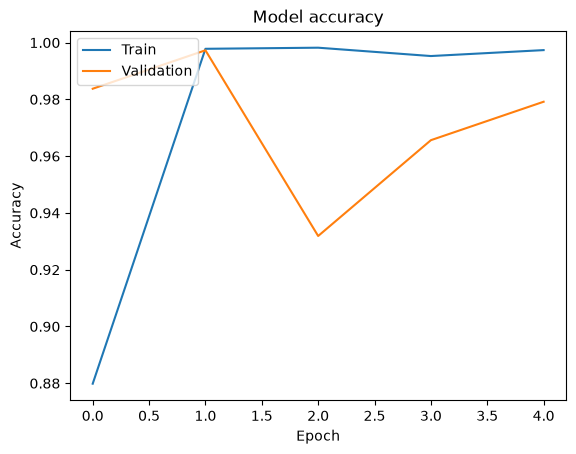

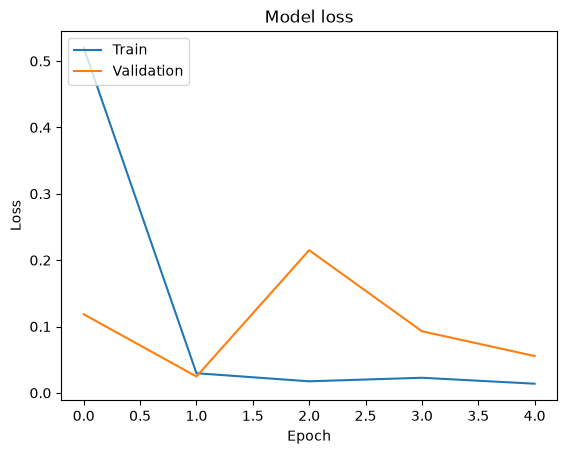

<Figure size 640x480 with 0 Axes>

In [39]:
# Plot training & validation accuracy values
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()
plt.tight_layout()
plt.show()

In [40]:
model.evaluate(X_val, y_val)
model.evaluate(X_mnist_val, y_mnist_val)

150/150 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.9973 - loss: 0.0246
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9995 - loss: 0.0100


[0.010023745708167553, 0.9994536638259888]

In [ ]:
model_filename = "kazim_cnn_v02.keras"
model.save("../models/" + model_filename)

In [42]:
test_df = pd.read_csv("../data/sign_mnist_test.csv")

print("Dataset shape: ", test_df.shape)
# display(test_df.head())

letters = "ABCDEFGHIKLMNOPQRSTUVWXY"

mapping = {
    ord(letter) - ord("A"): index
    for index, letter in enumerate(letters)
}

mapped_labels = test_df["label"].map(mapping)

if mapped_labels.isna().any():
    raise ValueError("Unexpected test labels found.")

y_test = mapped_labels.to_numpy(dtype=np.int64)

X_test = test_df.drop(columns=['label']).values
X_test = X_test.reshape(-1, 28, 28, 1)
X_test = X_test.astype('float32') / 255.0

Dataset shape:  (7172, 785)


In [43]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=64, verbose=1)
print("Test loss:", test_loss)
print("Test accuracy:" , test_accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9145 - loss: 0.3073
Test loss: 0.30728086829185486
Test accuracy: 0.9145287275314331


In [44]:
y_scores= model.predict(X_test, verbose=1)
y_pred = np.argmax(y_scores, axis=1)

labels = np.sort(np.unique(y_test))
label_names = [chr(int(label) + ord('A')) for label in labels]

225/225 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step


              precision    recall  f1-score   support

           A      0.997     0.991     0.994       331
           B      0.953     0.995     0.974       432
           C      1.000     0.994     0.997       310
           D      0.907     1.000     0.951       245
           E      0.917     1.000     0.957       498
           F      1.000     1.000     1.000       247
           G      1.000     0.753     0.859       348
           H      0.827     1.000     0.906       436
           I      0.912     0.896     0.904       288
           K      0.928     0.931     0.929       331
           L      1.000     1.000     1.000       209
           M      0.791     0.901     0.842       394
           N      0.904     0.646     0.754       291
           O      1.000     0.943     0.971       246
           P      0.961     1.000     0.980       347
           Q      1.000     0.915     0.955       164
           R      0.707     0.854     0.774       144
           S      0.847    

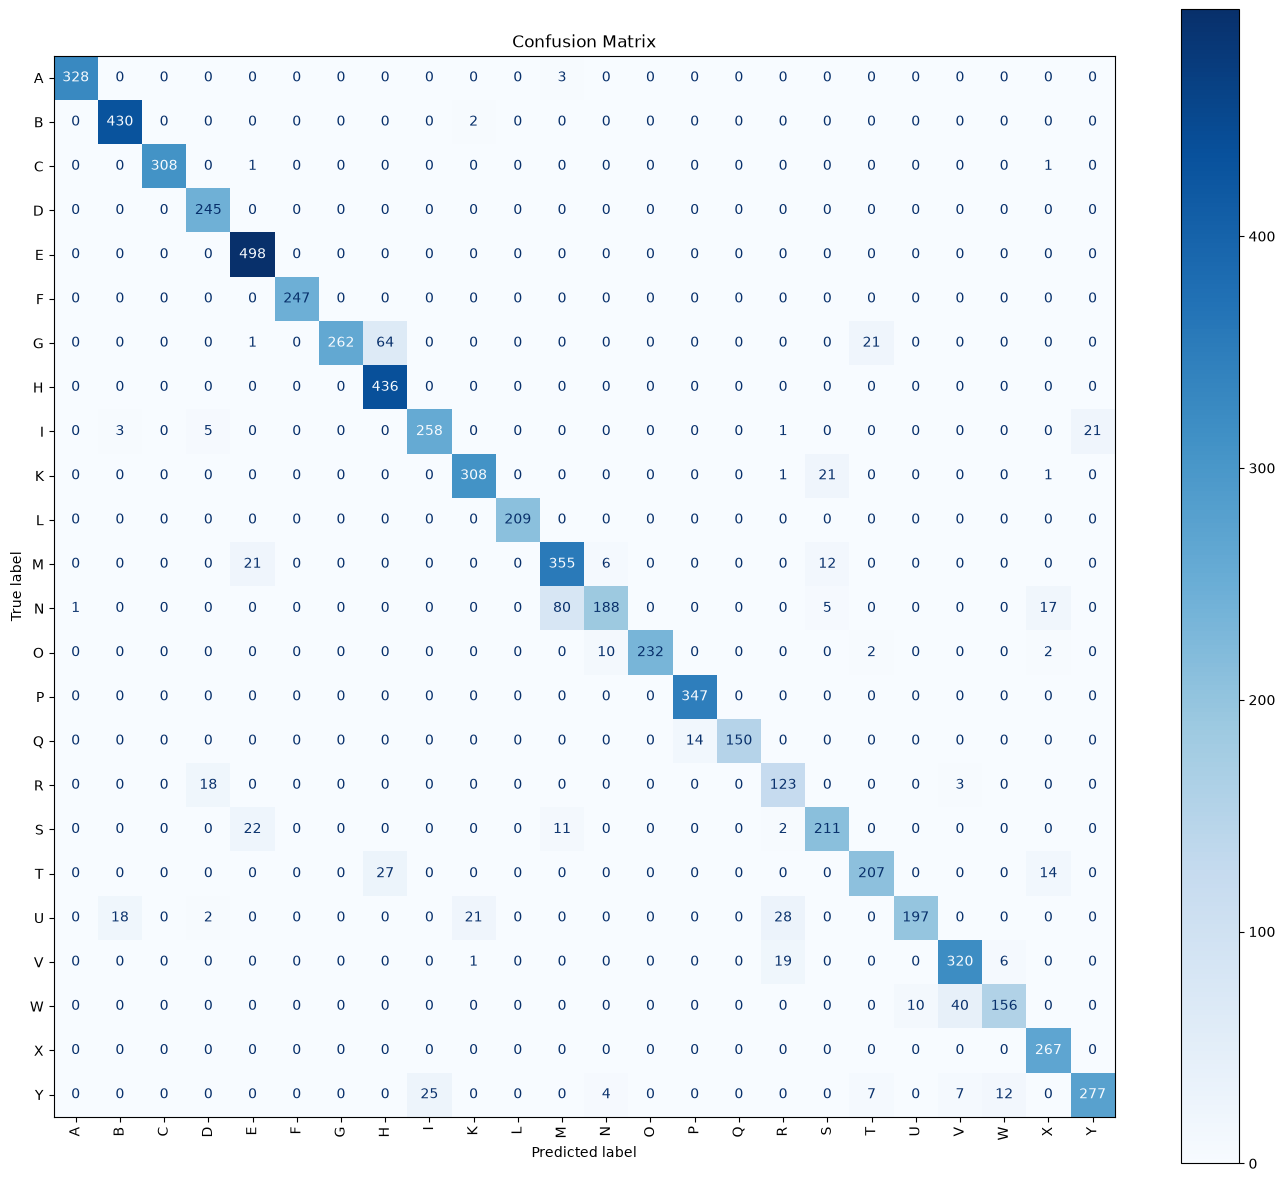

In [45]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)

letters = "ABCDEFGHIKLMNOPQRSTUVWXY"
labels = np.arange(24)

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=list(letters),
    digits=3,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=list(letters),
    cmap="Blues",
    values_format="d",
    ax=ax,
)

ax.set_title("Confusion Matrix")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [46]:
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2%}")

macro_f1_with_labels = f1_score(y_test, y_pred, labels=labels, average='macro', zero_division=0)
print(f"Macro F1 Score: {macro_f1_with_labels:.3f}")

Test Accuracy: 91.45%
Macro F1 Score: 0.909


In [47]:
from pathlib import Path
import math

import numpy as np
from PIL import Image, ImageOps


LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"
LABEL_MAP = {letter: index for index, letter in enumerate(LETTERS)}


def load_aslyset(root_directory, image_size=28):
    root = Path(root_directory)
    images_root = root / "images"
    labels_root = root / "labels"

    if not images_root.is_dir() or not labels_root.is_dir():
        raise FileNotFoundError(
            "Expected 'images' and 'labels' folders inside the dataset root."
        )

    extensions = {".jpg", ".jpeg", ".png"}

    images = []
    labels = []
    paths = []
    skipped = []

    for image_path in sorted(images_root.rglob("*")):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in extensions:
            continue

        # Letter comes from the containing folder.
        letter = image_path.parent.name.upper()

        # Excludes FN, SP and any other unsupported classes.
        if letter not in LABEL_MAP:
            continue

        # Preserve User/letter subfolders when locating annotations.
        relative_path = image_path.relative_to(images_root)
        annotation_path = (
            labels_root / relative_path
        ).with_suffix(".txt")

        try:
            rows = [
                row.split()
                for row in annotation_path.read_text().splitlines()
                if row.strip()
            ]

            # This loader expects one annotated hand per image.
            if len(rows) != 1 or len(rows[0]) != 5:
                raise ValueError(
                    "Expected one YOLO annotation with five values."
                )

            # Folder name supplies the CNN label.
            # Annotation class ID is deliberately not reused.
            _, xc, yc, box_width, box_height = map(float, rows[0])

            coordinates = np.array([xc, yc, box_width, box_height])

            if (
                not np.isfinite(coordinates).all()
                or not 0 <= xc <= 1
                or not 0 <= yc <= 1
                or not 0 < box_width <= 1
                or not 0 < box_height <= 1
            ):
                raise ValueError("Invalid normalized bounding box.")

            with Image.open(image_path) as original:
                # Keep stored orientation so annotations remain aligned.
                rgba = original.convert("RGBA")
                background = Image.new(
                    "RGBA", rgba.size, (255, 255, 255, 255)
                )
                image = Image.alpha_composite(
                    background, rgba
                ).convert("RGB")

                width, height = image.size

                # Convert normalized YOLO coordinates to pixel bounds.
                left = max(
                    0, math.floor((xc - box_width / 2) * width)
                )
                top = max(
                    0, math.floor((yc - box_height / 2) * height)
                )
                right = min(
                    width, math.ceil((xc + box_width / 2) * width)
                )
                bottom = min(
                    height, math.ceil((yc + box_height / 2) * height)
                )

                if right <= left or bottom <= top:
                    raise ValueError("Bounding box produces an empty crop.")

                hand = image.crop((left, top, right, bottom))
                grayscale = ImageOps.grayscale(hand)

                # Match your previous preprocessing:
                # preserve proportions and use white padding.
                prepared = ImageOps.pad(
                    grayscale,
                    (image_size, image_size),
                    method=Image.Resampling.LANCZOS,
                    color=255,
                )

                pixels = np.array(prepared, dtype=np.float32) / 255.0

            images.append(pixels)
            labels.append(LABEL_MAP[letter])
            paths.append(str(image_path))

        except (OSError, ValueError) as error:
            skipped.append((str(image_path), str(error)))

    if not images:
        raise ValueError(
            f"No usable images loaded. First issues: {skipped[:3]}"
        )

    X = np.stack(images)[..., np.newaxis]
    y = np.array(labels, dtype=np.int64)

    print(f"Loaded: {len(X)} images")
    print(f"Skipped due to missing/invalid files: {len(skipped)}")

    return X, y, paths, skipped

In [48]:
X_external, y_external, external_paths, skipped = load_aslyset(
    "../data/ASLYset"
)

print("Images:", X_external.shape)
print("Labels:", y_external.shape)
print("Pixel range:", X_external.min(), X_external.max())
print("Classes present:", [LETTERS[i] for i in np.unique(y_external)])

# Inspect any loading problems.
for path, reason in skipped[:5]:
    print(path, "->", reason)

Loaded: 4800 images
Skipped due to missing/invalid files: 0
Images: (4800, 28, 28, 1)
Labels: (4800,)
Pixel range: 0.0 1.0
Classes present: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


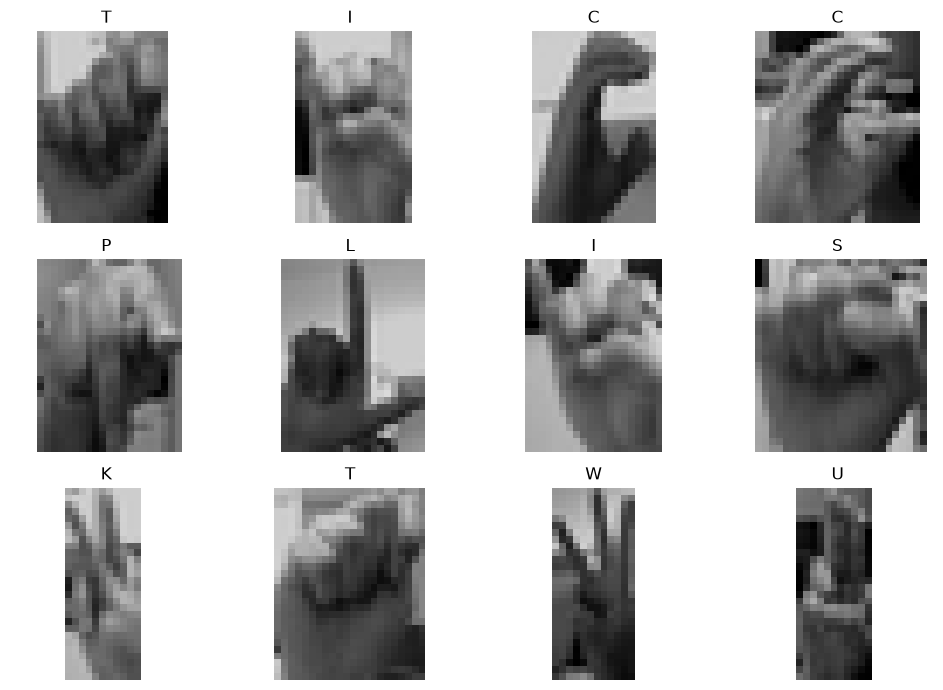

In [49]:
import matplotlib.pyplot as plt

indices = np.random.default_rng(42).choice(
    len(X_external),
    size=min(12, len(X_external)),
    replace=False,
)

fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for ax in axes.flat:
    ax.axis("off")

for ax, index in zip(axes.flat, indices):
    ax.imshow(
        X_external[index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(LETTERS[int(y_external[index])])

plt.tight_layout()
plt.show()

In [50]:
results = model.evaluate(
    X_external,
    y_external,
    batch_size=64,
    return_dict=True,
)

print(f"External test loss: {results['loss']:.4f}")
print(f"External test accuracy: {results['accuracy']:.2%}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.1619 - loss: 4.9652
External test loss: 4.9652
External test accuracy: 16.19%
